In [69]:
import tempfile

import numpy as np
import healpy as hp
from matplotlib import pyplot as plt

import litebird_sim as lbs
import ducc0
from time import time

from scipy.sparse import csr_matrix
from scipy.sparse.linalg import LinearOperator, cg

In [70]:
nside = 16
pol = True

In [71]:
epsilon = 1e-12
tol = epsilon
rtol = epsilon

In [72]:
lmax = 2 * nside
kmax = 2            #beam mmax
npix = hp.nside2npix(nside)

resol_arcmin = hp.nside2resol(nside, arcmin=True)
fwhm_arcmin = 3.5 * resol_arcmin

#LiteBIRD scans the sky at approximately 90 arcmin / sec
omega_scan = 90
fwhm_crossing_time = fwhm_arcmin / omega_scan
sampling_rate_hz = 1 / fwhm_crossing_time * 3.5

In [73]:
def setup_sim(nside, pol):
    ###############################################################################
    ####### Producing the input maps, pointings and TODs using litebird_sim #######
    ###############################################################################


    ### Mission parameters (one year of observation)
    start_time = 51
    mission_time_days = 365.25


    ### Simulation parameters
    random_seed = 0
    imo = lbs.Imo(flatfile_location=lbs.PTEP_IMO_LOCATION)
    dtype_float = np.float64
    tmp_dir = tempfile.TemporaryDirectory()


    ### Scanning strategy parameters (LiteBIRD-like)
    spin_sun_angle_deg = 37.5
    spin_sun_angle_rad = np.deg2rad(spin_sun_angle_deg)
    spin_boresight_angle_rad = np.deg2rad(95-spin_sun_angle_deg)
    spin_rate_hz = 0.3 / 60.0
    precession_rate_hz = 1/(192.348 * 60)


    ### Initializing the simulation
    sim = lbs.Simulation(
            random_seed=random_seed,
            base_path=tmp_dir.name,
            name="test",
            start_time=start_time,
            duration_s=mission_time_days * 24 * 60 * 60.0,
            imo=imo,
            )


    ### Instrument info
    instr_info = lbs.InstrumentInfo(
        spin_boresight_angle_rad = spin_boresight_angle_rad,
    )

    sim.set_instrument(instr_info)


    ### Scanning strategy
    sim.set_scanning_strategy(
        scanning_strategy=lbs.SpinningScanningStrategy(
            spin_sun_angle_rad=spin_sun_angle_rad,
            spin_rate_hz=spin_rate_hz,
            precession_rate_hz=precession_rate_hz,
        )
    )

    ### Channel info
    ch_info = lbs.FreqChannelInfo(
        bandcenter_ghz=100.0,                   # value for "MF1-100" from Option 1 IMo
        bandwidth_ghz=0.23,                     # value for "MF1-100" from Option 1 IMo
        fwhm_arcmin=fwhm_arcmin,
        sampling_rate_hz=sampling_rate_hz,
    )


    ### Detector list
    pol_angles_rad = [0.]
    n_detectors = len(pol_angles_rad)

    detector_list = []
    for i in range(n_detectors):
        det = ch_info.get_boresight_detector(name=f"Dummy_det_#{i+1}")
        det.pol_angle_rad = pol_angles_rad[i]
        detector_list.append(det)


    ### Create observations
    sim.create_observations(
            detectors=detector_list,
            num_of_obs_per_detector=1,
            n_blocks_det=1,
            n_blocks_time=1,
            split_list_over_processes=False,
            tod_dtype=dtype_float,
    )


    ### Input d0s0
    sky_params = lbs.SkyGenerationParams(
        make_cmb=False,
        make_fg=True,
        fg_models=["d0", "s0"],  # set the FG models you want
        apply_beam=False,  # if True, smooths the input map by the beam of the channel
        bandpass_integration=False,  # if True, integrates over the top-hat bandpass of the channel
        units="K_CMB",
        output_type="alm",
        nside=nside,
        lmax=lmax,
    )

    ### Remove polarization
    alms = sim.get_sky(parameters = sky_params, channels=ch_info, store_in_observation=True)

    if not pol:
        alms.values[1:] *= 0 

    ### Define Gaussian beams
    blms = sim.get_gauss_beam_alms(lmax=lmax, mmax=kmax)

    ### Prepare pointings
    sim.prepare_pointings()
    sim.precompute_pointings()

    return sim, alms, blms

In [74]:
### Define convolution parameters
Convparams = lbs.BeamConvolutionParameters(
    lmax = lmax,
    mmax = kmax,
    single_precision = False,
    epsilon = epsilon,
)

In [75]:
sim_None, alms, blms = setup_sim(nside, True)

sim_None.nullify_tod
# Scan the map and fill tod
lbs.add_convolved_sky_to_observations(
    sim_None.observations,
    alms,
    blms,
    convolution_params=Convparams,
)

tod_None = sim_None.observations[0].tod[0]


[2026-10-20 18:29:12,756 WARNING MPI#0000] MPI layer is already initialized. Reinitializing the entire RNG hierarchy.
[2026-10-20 18:29:12,756 WARNING MPI#0000] MPI layer is already initialized. Reinitializing the entire RNG hierarchy.
[2026-10-20 18:29:13,150 WARNING MPI#0000] seed_cmb is None. This could lead to unexpected behavior in MPI jobs.
[2026-10-20 18:29:13,150 INFO MPI#0000] Generating Foregrounds...
[2026-10-20 18:29:13,150 INFO MPI#0000] Retrieve data for pysm_2/dust_t_new.fits (if not cached already)
[2026-10-20 18:29:13,152 INFO MPI#0000] NSIDE = 512
[2026-10-20 18:29:13,152 INFO MPI#0000] ORDERING = RING in fits file
[2026-10-20 18:29:13,152 INFO MPI#0000] INDXSCHM = IMPLICIT
[2026-10-20 18:29:13,183 INFO MPI#0000] Retrieve data for pysm_2/dust_q_new.fits (if not cached already)
[2026-10-20 18:29:13,184 INFO MPI#0000] NSIDE = 512
[2026-10-20 18:29:13,184 INFO MPI#0000] ORDERING = RING in fits file
[2026-10-20 18:29:13,184 INFO MPI#0000] INDXSCHM = IMPLICIT
[2026-10-20 1

In [76]:
sim_nside, alms, blms = setup_sim(nside, True)

sim_nside.nullify_tod
# Scan the map and fill tod
lbs.add_convolved_sky_to_observations(
    sim_nside.observations,
    alms,
    blms,
    convolution_params=Convparams,
    nside_centering=nside, #ADDED
)

tod_nside = sim_nside.observations[0].tod[0]

[2026-10-20 18:29:17,345 WARNING MPI#0000] MPI layer is already initialized. Reinitializing the entire RNG hierarchy.
[2026-10-20 18:29:17,345 WARNING MPI#0000] MPI layer is already initialized. Reinitializing the entire RNG hierarchy.
[2026-10-20 18:29:17,729 WARNING MPI#0000] seed_cmb is None. This could lead to unexpected behavior in MPI jobs.
[2026-10-20 18:29:17,729 INFO MPI#0000] Generating Foregrounds...
[2026-10-20 18:29:17,729 INFO MPI#0000] Retrieve data for pysm_2/dust_t_new.fits (if not cached already)
[2026-10-20 18:29:17,731 INFO MPI#0000] NSIDE = 512
[2026-10-20 18:29:17,731 INFO MPI#0000] ORDERING = RING in fits file
[2026-10-20 18:29:17,731 INFO MPI#0000] INDXSCHM = IMPLICIT
[2026-10-20 18:29:17,762 INFO MPI#0000] Retrieve data for pysm_2/dust_q_new.fits (if not cached already)
[2026-10-20 18:29:17,763 INFO MPI#0000] NSIDE = 512
[2026-10-20 18:29:17,764 INFO MPI#0000] ORDERING = RING in fits file
[2026-10-20 18:29:17,764 INFO MPI#0000] INDXSCHM = IMPLICIT
[2026-10-20 1

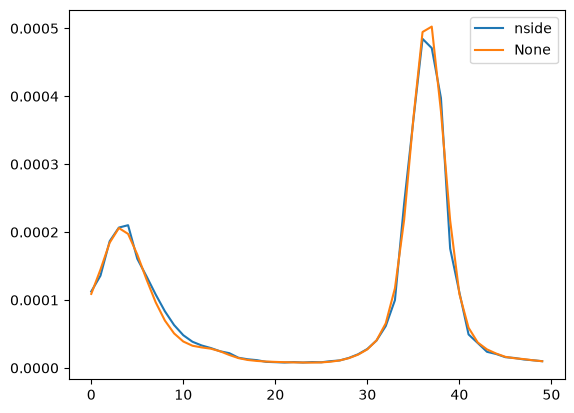

In [77]:
plt.plot(tod_nside[:50], label="nside")
plt.plot(tod_None[:50], label="None")
plt.legend()
plt.show()

In [78]:
#lbs_map_None = lbs.make_binned_map(nside=nside, observations=sim_None.observations).binned_map[0] #FIXME

In [79]:
#lbs_map_nside = lbs.make_binned_map(nside=nside, observations=sim_nside.observations).binned_map[0] #FIXME

In [80]:
### Binning
pointing_matrix_None = sim_None.observations[0].pointing_matrix

thetas_temp, phis_temp, psis_temp = pointing_matrix_None[0].T

# Ecliptic to Galactic
thetas_None, phis_None = hp.Rotator(coord="eg")(thetas_temp, phis_temp)
psis_None = psis_temp

pixs_None = hp.ang2pix(nside, thetas_None, phis_None)

n = len(pixs_None)
rows = np.repeat(np.arange(n), 3)
cols = (3 * pixs_None[:, None] + np.arange(3)).ravel()
data = np.column_stack((
    np.ones(n),
    np.cos(2 * psis_None),
    np.sin(2 * psis_None),
)).ravel()

response_matrix_None = csr_matrix(
    (data, (rows, cols)),
    shape=(n, 3 * npix),
)

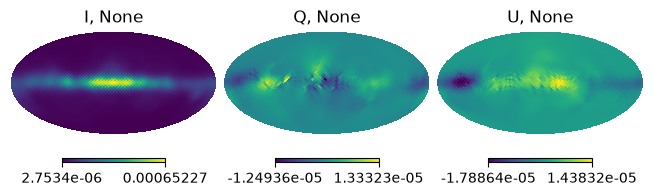

In [82]:
A = response_matrix_None.transpose().dot(response_matrix_None)
b = response_matrix_None.transpose().dot(tod_None)

# solve Ax = b
binned_map_temp = cg(A, b, rtol=rtol)

binned_map_None = np.empty((3,hp.nside2npix(nside)))
 
for i in range(hp.nside2npix(nside)):
    binned_map_None[0,i] = binned_map_temp[0][3*i]
    binned_map_None[1,i] = binned_map_temp[0][3*i+1]
    binned_map_None[2,i] = binned_map_temp[0][3*i+2]
    
hp.mollview(binned_map_None[0],sub=131, title="I, None")
hp.mollview(binned_map_None[1],sub=132, title="Q, None")
hp.mollview(binned_map_None[2],sub=133, title="U, None")

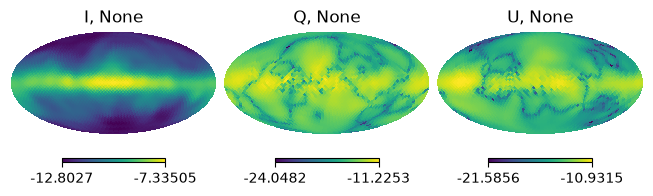

In [83]:
hp.mollview(np.log(np.abs(binned_map_None[0])),sub=131, title="I, None")
hp.mollview(np.log(np.abs(binned_map_None[1])),sub=132, title="Q, None")
hp.mollview(np.log(np.abs(binned_map_None[2])),sub=133, title="U, None")

In [84]:
### Binning
pointing_matrix_nside = sim_nside.observations[0].pointing_matrix

thetas_temp, phis_temp, psis_temp = pointing_matrix_nside[0].T

# Ecliptic to Galactic
thetas_nside, phis_nside = hp.Rotator(coord="eg")(thetas_temp, phis_temp)
psis_nside = psis_temp

pixs_nside = hp.ang2pix(nside, thetas_nside, phis_nside)

n = len(pixs_nside)
rows = np.repeat(np.arange(n), 3)
cols = (3 * pixs_nside[:, None] + np.arange(3)).ravel()
data = np.column_stack((
    np.ones(n),
    np.cos(2 * psis_nside),
    np.sin(2 * psis_nside),
)).ravel()

response_matrix_nside = csr_matrix(
    (data, (rows, cols)),
    shape=(n, 3 * npix),
)

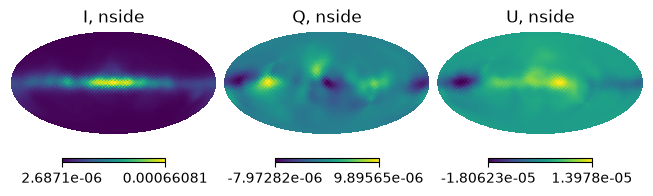

In [85]:
A = response_matrix_nside.transpose().dot(response_matrix_nside)
b = response_matrix_nside.transpose().dot(tod_nside)

# solve Ax = b
binned_map_temp = cg(A, b, rtol=rtol)

binned_map_nside = np.empty((3,hp.nside2npix(nside)))
 
for i in range(hp.nside2npix(nside)):
    binned_map_nside[0,i] = binned_map_temp[0][3*i]
    binned_map_nside[1,i] = binned_map_temp[0][3*i+1]
    binned_map_nside[2,i] = binned_map_temp[0][3*i+2]
    
hp.mollview(binned_map_nside[0],sub=131, title="I, nside")
hp.mollview(binned_map_nside[1],sub=132, title="Q, nside")
hp.mollview(binned_map_nside[2],sub=133, title="U, nside")

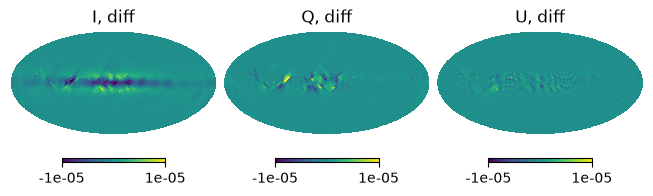

In [86]:
hp.mollview(binned_map_None[0] - binned_map_nside[0],sub=131, title="I, diff", min=-1e-5, max=1e-5)
hp.mollview(binned_map_None[1] - binned_map_nside[1],sub=132, title="Q, diff", min=-1e-5, max=1e-5)
hp.mollview(binned_map_None[2] - binned_map_nside[2],sub=133, title="U, diff", min=-1e-5, max=1e-5)

In [17]:
### Smooth sky alms (for comparison)
alms_in = np.copy(alms['100.0 GHz'].values[0])
alms_smoothed = hp.smoothalm(alms_in, fwhm=np.deg2rad(fwhm_arcmin/60))
map_smoothed = hp.alm2map(alms_smoothed, nside)

[2026-10-20 11:06:44,429 INFO MPI#0000] Sigma is 40.849669 arcmin (0.011883 rad) 
[2026-10-20 11:06:44,429 INFO MPI#0000] -> fwhm is 96.193620 arcmin
[2026-10-20 11:06:44,430 INFO MPI#0000] Sigma is 0.000000 arcmin (0.000000 rad) 
[2026-10-20 11:06:44,430 INFO MPI#0000] -> fwhm is 0.000000 arcmin


In [18]:
Cls_in = hp.alm2cl(alms_smoothed, lmax=lmax)

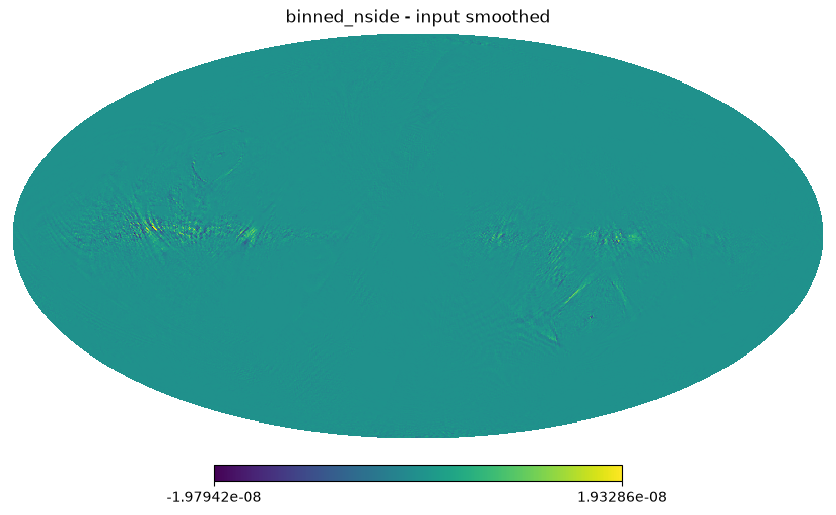

In [19]:
hp.mollview(map_smoothed - binned_map_nside[0], title="binned_nside - input smoothed")

In [20]:
Cls_map_None = hp.anafast(binned_map_None[0], lmax=lmax)
Cls_map_nside = hp.anafast(binned_map_nside[0], lmax=lmax)

In [21]:
pixwin = hp.pixwin(nside=nside,pol=False,lmax=lmax)

In [22]:
color_map_None = "#C73E1D"
color_map_nside = ""

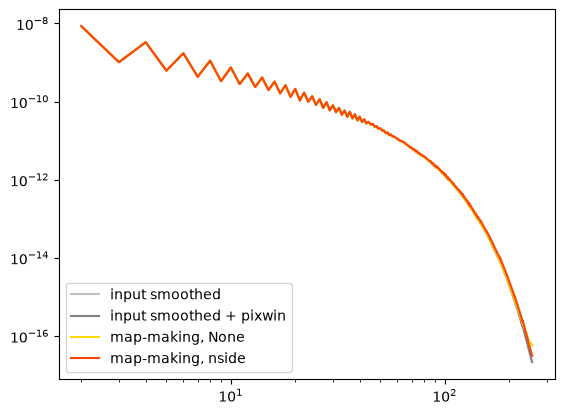

In [23]:
ell = np.arange(2,lmax+1)

plt.loglog(ell, Cls_in[ell], color="silver", label="input smoothed")
plt.loglog(ell, Cls_in[ell]*pixwin[ell]**2, color="gray", label="input smoothed + pixwin")
plt.loglog(ell, Cls_map_None[ell], color="gold", label="map-making, None")
plt.loglog(ell, Cls_map_nside[ell], color="orangered", label="map-making, nside")
plt.legend()
plt.show()

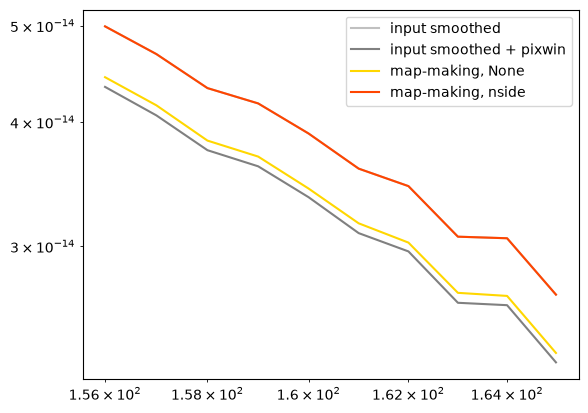

In [24]:
ell = np.arange(lmax-100,lmax-90)

plt.loglog(ell, Cls_in[ell], color="silver", label="input smoothed")
plt.loglog(ell, Cls_in[ell]*pixwin[ell]**2, color="gray", label="input smoothed + pixwin")
plt.loglog(ell, Cls_map_None[ell], color="gold", label="map-making, None")
plt.loglog(ell, Cls_map_nside[ell], color="orangered", label="map-making, nside")
plt.legend()
plt.show()

In [ ]:
### alm-making
# code adapted from https://github.com/mreineck/ducc/blob/ducc0/python/demos/sht_general.py
# and https://github.com/healpy/healpy/blob/446185ae8b3ef97b863d2726b1dd711a3f4d153f/lib/healpy/sphtfunc.py

spin = 0
epsilon = epsilon
nthreads = 8
maxiter = 20
ncomp = 1
tol = tol

npoints = len(pixs_None)
loc = np.empty((npoints,2), dtype=np.float64)
loc[:,0] = thetas_None
loc[:,1] = np.where(phis_None > 0, phis_None, phis_None+2*np.pi)

# helper functions to convert between real- and complex-valued a_lm
def alm2realalm(alm):
    alm = alm.reshape((ncomp, -1))
    res = np.zeros((ncomp, alm.shape[1] * 2 - lmax - 1))
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1].real
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.float64) * np.sqrt(2.0)
    return res.reshape((-1,))

def realalm2alm(alm):
    alm = np.array(alm).reshape((ncomp, -1))
    res = np.zeros((ncomp, (alm.shape[1] + lmax + 1) // 2), dtype=np.complex128)
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1]
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.complex128) * (
            np.sqrt(2.0) / 2
        )
    if ncomp == 1:
        res = res[0]
    return res

def a2t2(x):
    talm = realalm2alm(x)
    res = ducc0.sht.synthesis_general(lmax=lmax, mmax=lmax, alm=np.array([talm]), loc=loc, spin=spin, epsilon=epsilon, nthreads=nthreads)
    return res.reshape((-1,))

def t2a2(x):
    talm = ducc0.sht.adjoint_synthesis_general(lmax=lmax, mmax=lmax, map=np.array([x]), loc=loc, spin=spin, epsilon=epsilon, nthreads=nthreads)
    res = alm2realalm(talm)
    return res

def ATA_func(x):
    return t2a2(a2t2(x))

def ATA_trans_func(x):
    return a2t2(t2a2(x))

b = t2a2(tod_None)

# We are explicitly setting "dtype" for the LinearOperator here because
# some (inadvertent?) changes in scipy 1.15 made this necessary
# (see, e.g., https://github.com/scipy/scipy/issues/22310).
op = LinearOperator(
    matvec=ATA_func, shape=(b.size, b.size),
    dtype=b.real.dtype
)

res = cg(
    A=op,
    b=b,
    x0=b,
    atol=tol,
    rtol=tol,
)

alm_ducc_None_None = realalm2alm(res[0])

[2026-10-20 11:07:51,386 INFO MPI#0000] Sigma is 0.000000 arcmin (0.000000 rad) 
[2026-10-20 11:07:51,388 INFO MPI#0000] -> fwhm is 0.000000 arcmin


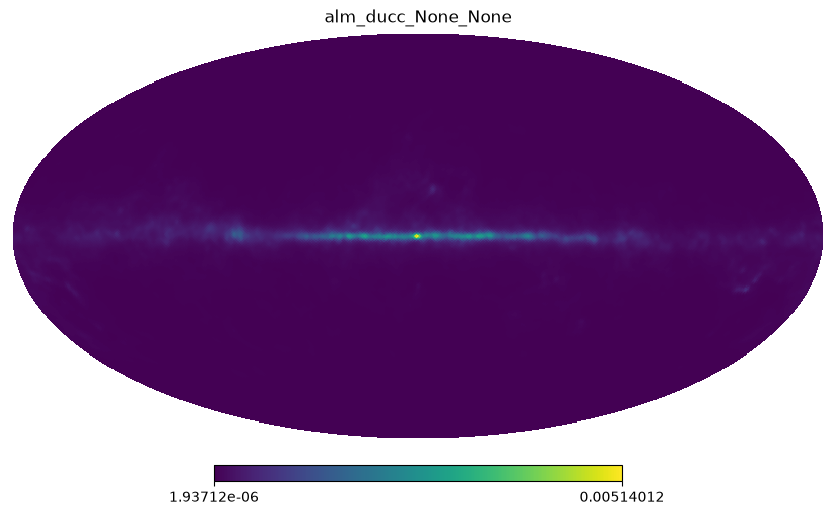

In [26]:
hp.mollview(hp.alm2map(alm_ducc_None_None, nside=nside), title="alm_ducc_None_None")

In [27]:
### alm-making
# code adapted from https://github.com/mreineck/ducc/blob/ducc0/python/demos/sht_general.py
# and https://github.com/healpy/healpy/blob/446185ae8b3ef97b863d2726b1dd711a3f4d153f/lib/healpy/sphtfunc.py

spin = 0
epsilon = epsilon
nthreads = 8
maxiter = 20
ncomp = 1
tol = tol

thetas, phis = hp.pix2ang(nside, pixs_nside) #ADDED

npoints = len(pixs_nside)
loc = np.empty((npoints,2), dtype=np.float64)
loc[:,0] = thetas
loc[:,1] = np.where(phis > 0, phis, phis+2*np.pi)

# helper functions to convert between real- and complex-valued a_lm
def alm2realalm(alm):
    alm = alm.reshape((ncomp, -1))
    res = np.zeros((ncomp, alm.shape[1] * 2 - lmax - 1))
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1].real
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.float64) * np.sqrt(2.0)
    return res.reshape((-1,))

def realalm2alm(alm):
    alm = np.array(alm).reshape((ncomp, -1))
    res = np.zeros((ncomp, (alm.shape[1] + lmax + 1) // 2), dtype=np.complex128)
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1]
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.complex128) * (
            np.sqrt(2.0) / 2
        )
    if ncomp == 1:
        res = res[0]
    return res

def a2t2(x):
    talm = realalm2alm(x)
    res = ducc0.sht.synthesis_general(lmax=lmax, mmax=lmax, alm=np.array([talm]), loc=loc, spin=spin, epsilon=epsilon, nthreads=nthreads)
    return res.reshape((-1,))

def t2a2(x):
    talm = ducc0.sht.adjoint_synthesis_general(lmax=lmax, mmax=lmax, map=np.array([x]), loc=loc, spin=spin, epsilon=epsilon, nthreads=nthreads)
    res = alm2realalm(talm)
    return res

def ATA_func(x):
    return t2a2(a2t2(x))

def ATA_trans_func(x):
    return a2t2(t2a2(x))

b = t2a2(tod_None)

# We are explicitly setting "dtype" for the LinearOperator here because
# some (inadvertent?) changes in scipy 1.15 made this necessary
# (see, e.g., https://github.com/scipy/scipy/issues/22310).
op = LinearOperator(
    matvec=ATA_func, shape=(b.size, b.size),
    dtype=b.real.dtype
)

res = cg(
    A=op,
    b=b,
    x0=b,
    atol=tol,
    rtol=tol,
)

alm_ducc_None_nside = realalm2alm(res[0])

[2026-10-20 11:09:00,580 INFO MPI#0000] Sigma is 0.000000 arcmin (0.000000 rad) 
[2026-10-20 11:09:00,582 INFO MPI#0000] -> fwhm is 0.000000 arcmin


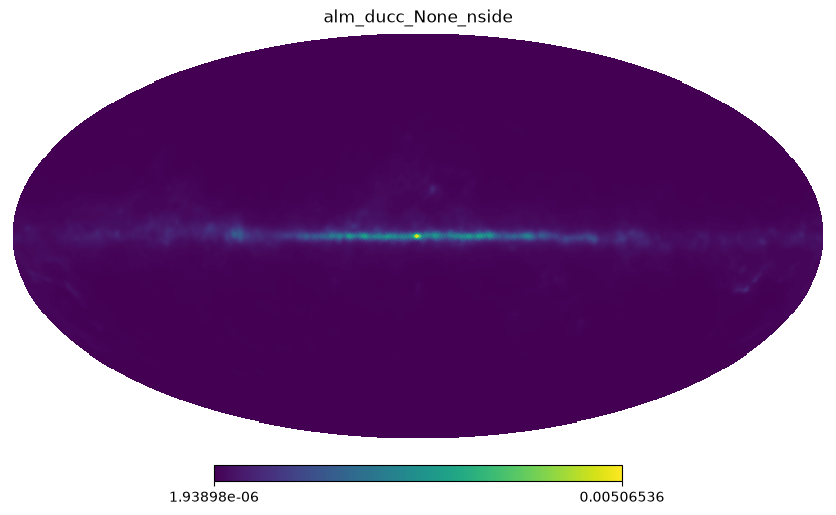

In [28]:
hp.mollview(hp.alm2map(alm_ducc_None_nside, nside=nside), title="alm_ducc_None_nside")

In [29]:
### alm-making
# code adapted from https://github.com/mreineck/ducc/blob/ducc0/python/demos/sht_general.py
# and https://github.com/healpy/healpy/blob/446185ae8b3ef97b863d2726b1dd711a3f4d153f/lib/healpy/sphtfunc.py

spin = 0
epsilon = epsilon
nthreads = 8
maxiter = 20
ncomp = 1
tol = tol

thetas, phis = hp.pix2ang(nside, pixs_nside) #ADDED

npoints = len(pixs_nside)
loc = np.empty((npoints,2), dtype=np.float64)
loc[:,0] = thetas
loc[:,1] = np.where(phis > 0, phis, phis+2*np.pi)

# helper functions to convert between real- and complex-valued a_lm
def alm2realalm(alm):
    alm = alm.reshape((ncomp, -1))
    res = np.zeros((ncomp, alm.shape[1] * 2 - lmax - 1))
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1].real
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.float64) * np.sqrt(2.0)
    return res.reshape((-1,))

def realalm2alm(alm):
    alm = np.array(alm).reshape((ncomp, -1))
    res = np.zeros((ncomp, (alm.shape[1] + lmax + 1) // 2), dtype=np.complex128)
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1]
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.complex128) * (
            np.sqrt(2.0) / 2
        )
    if ncomp == 1:
        res = res[0]
    return res

def a2t2(x):
    talm = realalm2alm(x)
    res = ducc0.sht.synthesis_general(lmax=lmax, mmax=lmax, alm=np.array([talm]), loc=loc, spin=spin, epsilon=epsilon, nthreads=nthreads)
    return res.reshape((-1,))

def t2a2(x):
    talm = ducc0.sht.adjoint_synthesis_general(lmax=lmax, mmax=lmax, map=np.array([x]), loc=loc, spin=spin, epsilon=epsilon, nthreads=nthreads)
    res = alm2realalm(talm)
    return res

def ATA_func(x):
    return t2a2(a2t2(x))

def ATA_trans_func(x):
    return a2t2(t2a2(x))

b = t2a2(tod_nside)

# We are explicitly setting "dtype" for the LinearOperator here because
# some (inadvertent?) changes in scipy 1.15 made this necessary
# (see, e.g., https://github.com/scipy/scipy/issues/22310).
op = LinearOperator(
    matvec=ATA_func, shape=(b.size, b.size),
    dtype=b.real.dtype
)

res = cg(
    A=op,
    b=b,
    x0=b,
    atol=tol,
    rtol=tol,
)

alm_ducc_nside_nside = realalm2alm(res[0])

[2026-10-20 11:10:07,583 INFO MPI#0000] Sigma is 0.000000 arcmin (0.000000 rad) 
[2026-10-20 11:10:07,584 INFO MPI#0000] -> fwhm is 0.000000 arcmin


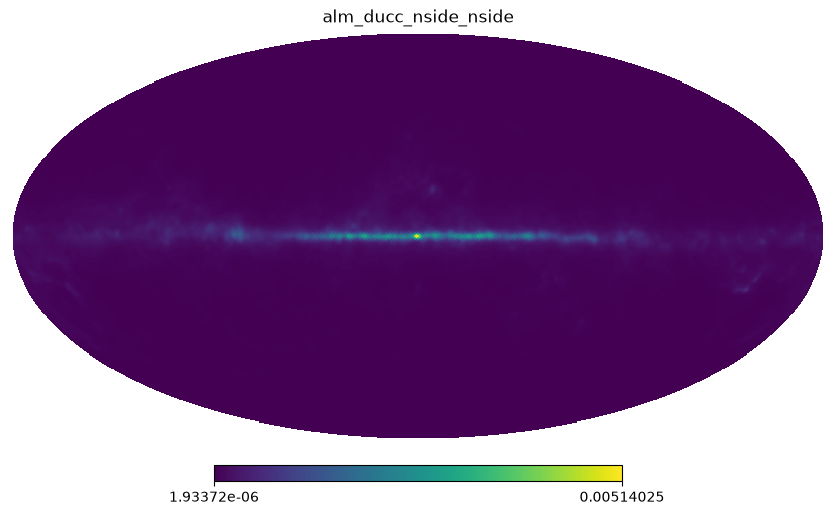

In [30]:
hp.mollview(hp.alm2map(alm_ducc_nside_nside, nside=nside), title="alm_ducc_nside_nside")

[2026-10-20 11:10:07,676 INFO MPI#0000] Sigma is 0.000000 arcmin (0.000000 rad) 
[2026-10-20 11:10:07,677 INFO MPI#0000] -> fwhm is 0.000000 arcmin


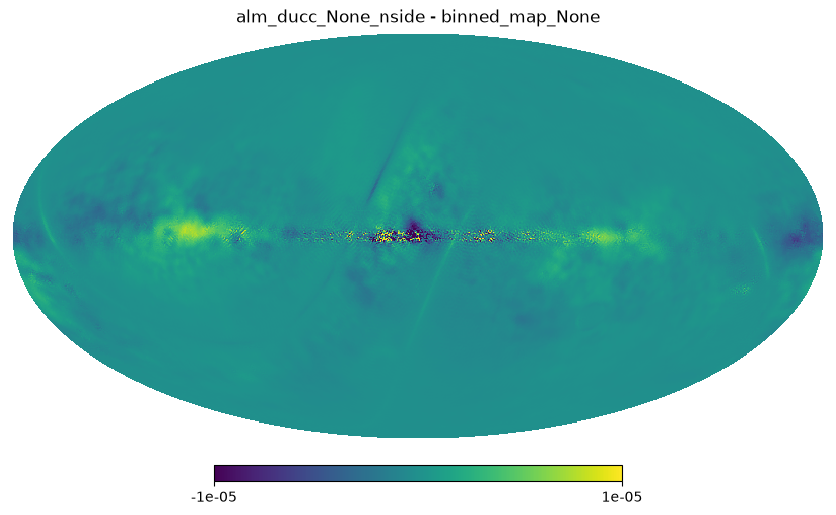

In [31]:
hp.mollview(hp.alm2map(alm_ducc_None_nside, nside=nside) - binned_map_None[0], title="alm_ducc_None_nside - binned_map_None", min=-1e-5, max=1e-5)

In [32]:
Cls_alm_None_None = hp.alm2cl(alm_ducc_None_None, lmax=lmax)
Cls_alm_None_nside = hp.alm2cl(alm_ducc_None_nside, lmax=lmax)
Cls_alm_nside_nside = hp.alm2cl(alm_ducc_nside_nside, lmax=lmax)

In [33]:
linestyle_map = "-"
linestyle_alm = "--"

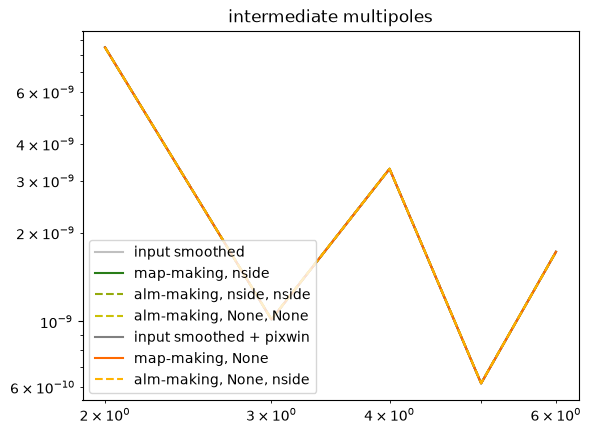

In [34]:
ell = np.arange(2, 2+5)

plt.loglog(ell, Cls_in[ell], color="silver", label="input smoothed")
plt.loglog(ell, Cls_map_nside[ell], color="#297D18", linestyle=linestyle_map, label="map-making, nside")
plt.loglog(ell, Cls_alm_nside_nside[ell], color="#94AA0C", linestyle=linestyle_alm, label="alm-making, nside, nside")
plt.loglog(ell, Cls_alm_None_None[ell], color="#CAC106", linestyle=linestyle_alm, label="alm-making, None, None")
plt.loglog(ell, Cls_in[ell]*pixwin[ell]**2, color="gray", label="input smoothed + pixwin")
plt.loglog(ell, Cls_map_None[ell], color="#FF6A00", linestyle=linestyle_map, label="map-making, None")
plt.loglog(ell, Cls_alm_None_nside[ell], color="#FFB300", linestyle=linestyle_alm, label="alm-making, None, nside")
plt.legend(loc="lower left")
plt.title("intermediate multipoles")
plt.show()

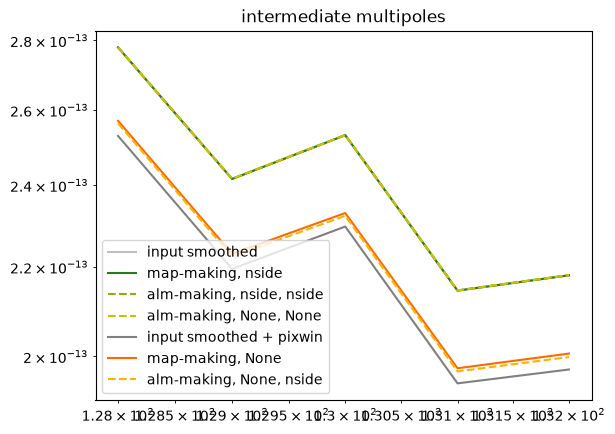

In [35]:
ell = np.arange(nside, nside+5)

plt.loglog(ell, Cls_in[ell], color="silver", label="input smoothed")
plt.loglog(ell, Cls_map_nside[ell], color="#297D18", linestyle=linestyle_map, label="map-making, nside")
plt.loglog(ell, Cls_alm_nside_nside[ell], color="#94AA0C", linestyle=linestyle_alm, label="alm-making, nside, nside")
plt.loglog(ell, Cls_alm_None_None[ell], color="#CAC106", linestyle=linestyle_alm, label="alm-making, None, None")
plt.loglog(ell, Cls_in[ell]*pixwin[ell]**2, color="gray", label="input smoothed + pixwin")
plt.loglog(ell, Cls_map_None[ell], color="#FF6A00", linestyle=linestyle_map, label="map-making, None")
plt.loglog(ell, Cls_alm_None_nside[ell], color="#FFB300", linestyle=linestyle_alm, label="alm-making, None, nside")
plt.legend(loc="lower left")
plt.title("intermediate multipoles")
plt.show()

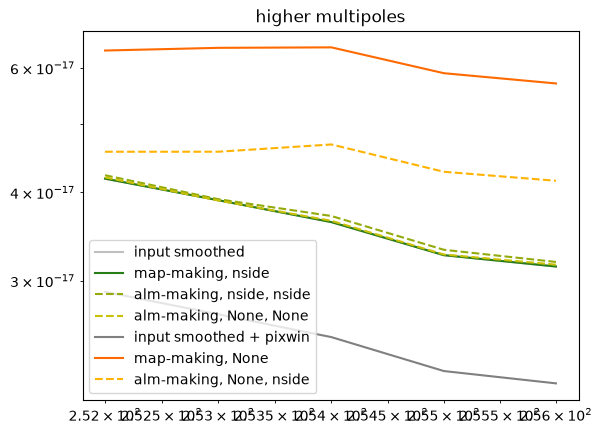

In [36]:
ell = np.arange(lmax+1-5, lmax+1)

plt.loglog(ell, Cls_in[ell], color="silver", label="input smoothed")
plt.loglog(ell, Cls_map_nside[ell], color="#297D18", linestyle=linestyle_map, label="map-making, nside")
plt.loglog(ell, Cls_alm_nside_nside[ell], color="#94AA0C", linestyle=linestyle_alm, label="alm-making, nside, nside")
plt.loglog(ell, Cls_alm_None_None[ell], color="#CAC106", linestyle=linestyle_alm, label="alm-making, None, None")
plt.loglog(ell, Cls_in[ell]*pixwin[ell]**2, color="gray", label="input smoothed + pixwin")
plt.loglog(ell, Cls_map_None[ell], color="#FF6A00", linestyle=linestyle_map, label="map-making, None")
plt.loglog(ell, Cls_alm_None_nside[ell], color="#FFB300", linestyle=linestyle_alm, label="alm-making, None, nside")
plt.legend(loc="lower left")
plt.title("higher multipoles")
plt.show()

In [ ]:
### alm-making
# code adapted from https://github.com/mreineck/ducc/blob/ducc0/python/demos/sht_general.py
# and https://github.com/healpy/healpy/blob/446185ae8b3ef97b863d2726b1dd711a3f4d153f/lib/healpy/sphtfunc.py

epsilon = epsilon
nthreads = 8
maxiter = 20
tol = tol

if pol:
    ncomp = 3
else:
    ncomp = 1

npoints = len(pixs_None)
loc = np.empty((npoints,2), dtype=np.float64)
loc[:,0] = thetas_None
loc[:,1] = np.where(phis_None > 0, phis_None, phis_None+2*np.pi)

def nalm(lmax, mmax):
    return ((mmax+1)*(mmax+2))//2 + (mmax+1)*(lmax-mmax)

n_alm = nalm(lmax,lmax)

# helper functions to convert between real- and complex-valued a_lm
def alm2realalm(alm):
    #alm = alm.reshape((ncomp, -1)) #MM: had to comment this
    res = np.zeros((ncomp, alm.shape[1] * 2 - lmax - 1))
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1].real
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.float64) * np.sqrt(2.0)
    return res.reshape((-1,))

def realalm2alm(alm):
    alm = np.array(alm).reshape((ncomp, -1))
    res = np.zeros((ncomp, (alm.shape[1] + lmax + 1) // 2), dtype=np.complex128)
    for i in range(ncomp):
        res[i, 0 : lmax + 1] = alm[i, 0 : lmax + 1]
        res[i, lmax + 1 :] = alm[i, lmax + 1 :].view(np.complex128) * (
            np.sqrt(2.0) / 2
        )
    if ncomp == 1:
        res = res[0]
    return res

if pol:
    def a2t2(x):
        talm = realalm2alm(x)
        res_I = ducc0.sht.synthesis_general(lmax=lmax, mmax=lmax, alm=np.array([talm[0]]), loc=loc, spin=0, epsilon=epsilon, nthreads=nthreads)
        res_P = ducc0.sht.synthesis_general(lmax=lmax, mmax=lmax, alm=talm[1:], loc=loc, spin=2, epsilon=epsilon, nthreads=nthreads)
        res = res_I + res_P[0] + res_P[1]
        return res.reshape((-1,))
else:
    def a2t2(x):
        talm = realalm2alm(x)
        res = ducc0.sht.synthesis_general(lmax=lmax, mmax=lmax, alm=np.array([talm]), loc=loc, spin=0, epsilon=epsilon, nthreads=nthreads)
        return res.reshape((-1,))
    
if pol:
    def t2a2(x):
            talm_I = ducc0.sht.adjoint_synthesis_general(lmax=lmax, mmax=lmax, map=np.array([x]), loc=loc, spin=0, epsilon=epsilon, nthreads=nthreads)
            #talm_P = ducc0.sht.adjoint_synthesis_general(lmax=lmax, mmax=lmax, map=np.array([x]), loc=loc, spin=2, epsilon=epsilon, nthreads=nthreads)
            res = alm2realalm(np.append(talm_I,np.zeros_like(talm_I),np.zeros_like(talm_I)))
            return res
else:
    def t2a2(x):
        talm = ducc0.sht.adjoint_synthesis_general(lmax=lmax, mmax=lmax, map=np.array([x]), loc=loc, spin=0, epsilon=epsilon, nthreads=nthreads)
        res = alm2realalm(talm)
        return res


In [173]:
alms_val = np.array(alms["100.0 GHz"].values)
realalms_val = alm2realalm(alms_val)

In [167]:
t_pol = a2t2(realalms_val)
a_pol = t2a2(t_pol)

TypeError: only integer scalar arrays can be converted to a scalar index

In [141]:
def random_alm(lmax, mmax, spin, ncomp, rng):
    res = rng.uniform(-1., 1., (ncomp, nalm(lmax, mmax))) \
     + 1j*rng.uniform(-1., 1., (ncomp, nalm(lmax, mmax)))
    # make a_lm with m==0 real-valued
    res[:, 0:lmax+1].imag = 0.
    ofs=0
    for s in range(spin):
        res[:, ofs:ofs+spin-s] = 0.
        ofs += lmax+1-s
    return res

In [ ]:
test = random_alm(lmax,lmax,2,2,np.random.default_rng(42))
np.shape(test)

(2, 561)

In [147]:
np.shape(alms_val[1:])

(2, 561)

In [ ]:
realalms_val = alm2realalm(alms_val)

In [111]:
np.array(realalms_val).reshape((ncomp, -1))

array([[ 2.17373433e-04, -2.05806659e-06, -1.99267503e-04, ...,
         2.27083531e-06,  5.36077246e-06, -8.35238601e-06],
       [ 0.00000000e+00,  0.00000000e+00, -8.23297638e-06, ...,
         1.03661674e-07,  1.87297894e-07,  4.40362492e-08],
       [ 0.00000000e+00,  0.00000000e+00,  6.33297516e-07, ...,
         1.11865523e-09, -1.84105102e-07,  4.89896775e-08]],
      shape=(3, 1089))

In [112]:
realalm2alm(realalms_val)

array([[ 2.17373433e-04+0.00000000e+00j, -2.05806659e-06+0.00000000e+00j,
        -1.99267503e-04+0.00000000e+00j, ...,
         2.84448371e-07+4.79571533e-06j, -1.26685008e-07+1.60572305e-06j,
         3.79063856e-06-5.90602879e-06j],
       [ 0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
        -8.23297638e-06+0.00000000e+00j, ...,
        -1.75990107e-07-1.76916392e-07j, -3.02626469e-08+7.32998723e-08j,
         1.32439611e-07+3.11383304e-08j],
       [ 0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         6.33297516e-07+0.00000000e+00j, ...,
         1.54689134e-07+6.19329103e-10j, -2.96445125e-08+7.91008696e-10j,
        -1.30181966e-07+3.46409332e-08j]], shape=(3, 561))

In [57]:
a2t2(alms["100.0 GHz"].values)

ValueError: could not broadcast input array from shape (528,) into shape (264,)

In [ ]:


if pol:
    print("TBD")
    quit()
else:
    def t2a2(x):
        talm = ducc0.sht.adjoint_synthesis_general(lmax=lmax, mmax=lmax, map=np.array([x]), loc=loc, spin=0, epsilon=epsilon, nthreads=nthreads)
        res = alm2realalm(talm)
        return res

def ATA_func(x):
    return t2a2(a2t2(x))

def ATA_trans_func(x):
    return a2t2(t2a2(x))

b = t2a2(tod_None)

# We are explicitly setting "dtype" for the LinearOperator here because
# some (inadvertent?) changes in scipy 1.15 made this necessary
# (see, e.g., https://github.com/scipy/scipy/issues/22310).
op = LinearOperator(
    matvec=ATA_func, shape=(b.size, b.size),
    dtype=b.real.dtype
)

res = cg(
    A=op,
    b=b,
    x0=b,
    atol=tol,
    rtol=tol,
)

alm_ducc_None_None = realalm2alm(res[0])

In [15]:
print(b.shape)

(1089,)


In [53]:
def nalm(lmax, mmax):
    return ((mmax+1)*(mmax+2))//2 + (mmax+1)*(lmax-mmax)

n_alm = nalm(lmax,lmax)
n_realalm = n_alm * 2 - lmax - 1

n_realalm

1089

In [56]:
alm2realalm(alms["100.0 GHz"].values)


array([ 2.17373433e-04, -2.05806659e-06, -1.99267503e-04, ...,
        1.11865523e-09, -1.84105102e-07,  4.89896775e-08], shape=(3267,))

In [46]:
print(len(blms["Dummy_det_#1"].values[2]))

96
